In [1]:
# 1B: CSV -> Parquet with small dtypes (one-time)
import pandas as pd, numpy as np, time
from pathlib import Path

ROOT = Path.home() / "Documents/uplift"
RAW = ROOT / "data/raw/criteo-uplift-v2.1.csv.gz"
PQ = ROOT / "data/processed/criteo.parquet"
F = [f"f{i}" for i in range(12)]

dtypes = {c: "float32" for c in F} | {c: "int8" for c in ["treatment", "conversion", "visit", "exposure"]}
t0 = time.time()
df = pd.read_csv(RAW, dtype=dtypes)
df.to_parquet(PQ, index=False)
print(df.shape, f"| {df.memory_usage().sum() / 1e9:.2f} GB in memory | {time.time() - t0:.0f}s")

(13979592, 16) | 0.73 GB in memory | 9s


In [2]:
## STEP 1C AUDIT 
df = pd.read_parquet(PQ)
print("missing values:", int(df.isna().sum().sum()))
print(df[["treatment", "exposure", "visit", "conversion"]].mean().round(4))
print(pd.crosstab(df["treatment"], df["exposure"], margins = True))

#outcome rate by arm
print(df.groupby("treatment")[["visit","conversion"]].agg(["mean", "size"]).round(5))

# randomization check standarized mean differnce smd per feature
m = df.groupby("treatment")[F].mean()
v = df.groupby("treatment")[F].var()

smd = (m.loc[1] - m.loc[0]) / np.sqrt((v.loc[1] + v.loc[0]) /2)
print("SMD (treated vs control):\n", smd.round(4).to_string())
print(df[F].nunique().to_string())

missing values: 0
treatment     0.8500
exposure      0.0306
visit         0.0470
conversion    0.0029
dtype: float64
exposure          0       1       All
treatment                            
0           2096937       0   2096937
1          11454443  428212  11882655
All        13551380  428212  13979592
             visit           conversion          
              mean      size       mean      size
treatment                                        
0          0.03820   2096937    0.00194   2096937
1          0.04854  11882655    0.00309  11882655
SMD (treated vs control):
 f0    -0.0069
f1     0.0232
f2    -0.0064
f3    -0.0489
f4     0.0068
f5    -0.0295
f6    -0.0405
f7     0.0208
f8    -0.0229
f9     0.0242
f10    0.0092
f11   -0.0052
f0     2181959
f1          60
f2      808663
f3         552
f4         260
f5         132
f6        1645
f7      622143
f8        3743
f9        1594
f10     483634
f11        136


In [3]:
# visit rate by f3 decile, control group only (no ad effect)
c = df[df["treatment"] == 0]
print(c.groupby(pd.qcut(c["f3"], 10, duplicates="drop"), observed=True)["visit"].mean().round(4))
print(c["f3"].value_counts(normalize=True).head(5).round(3))

f3
(-8.399, 2.935]    0.1025
(2.935, 4.68]      0.0305
Name: visit, dtype: float64
f3
4.679882    0.830
3.907662    0.041
3.359763    0.022
2.934780    0.015
2.587543    0.011
Name: proportion, dtype: float64


In [4]:
import pandas as pd, numpy as np
from pathlib import Path
from scipy import stats
import statsmodels.api as sm

t = df["treatment"].to_numpy()

In [5]:
#STEP 2A
#intent to treat effect difference in proportions

def ab_diff(y,t):
    y1,y0 = y[t==1], y[t==0]
    p1,p0 = y1.mean(), y0.mean()
    se = np.sqrt(p1*(1-p1) / len(y1) + p0 * (1-p0) / len(y0))
    d = p1-p0
    return dict(p0 = p0, p1 = p1, diff = d, se = se , lo = d - 1.96 * se, hi = d + 1.96 * se, rel = d / p0, z = d/ se)
res = {k: ab_diff(df[k].to_numpy(),t) for k in ["visit", "conversion"]}

for k, r in res.items():
    print(f"{k:10s} control {r['p0']:.4%} | treated {r['p1']:.4%} | lift {r['diff']*100:+.3f} pts "
          f"[{r['lo']*100:.3f}, {r['hi']*100:.3f}] | relative {r['rel']:+.1%} | z = {r['z']:.0f}")
    


visit      control 3.8201% | treated 4.8543% | lift +1.034 pts [1.006, 1.063] | relative +27.1% | z = 71
conversion control 0.1938% | treated 0.3089% | lift +0.115 pts [0.108, 0.122] | relative +59.4% | z = 34


In [6]:
#STEP 2B REGRESSION ADJUSTMENT  DOES THE LIFT SURVIVE CONTROLLING FOR THE FEATURE
Xr = sm.add_constant(df[["treatment"] + F].astype("float64"))

for k in ["visit", "conversion"]:
    fit = sm.OLS(df[k].astype("float64"), Xr).fit(cov_type="HC1")
    b, se = fit.params["treatment"], fit.bse["treatment"]
    print(f"{k:10s} adjusted {b*100:+.3f} pts [{(b-1.96*se)*100:.3f}, {(b+1.96*se)*100:.3f}] "
        f"| raw {res[k]['diff']*100:+.3f} | SE raw {res[k]['se']*100:.4f} vs adjusted {se*100:.4f}")
del Xr

visit      adjusted +0.698 pts [0.673, 0.723] | raw +1.034 | SE raw 0.0146 vs adjusted 0.0126
conversion adjusted +0.092 pts [0.085, 0.098] | raw +0.115 | SE raw 0.0034 vs adjusted 0.0032


In [7]:
#STEP 2B-2 randomization check with a model (AUC = .5 IS RANDOM)
import lightgbm as lgb
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import roc_auc_score

s = df.sample(2_000_000, random_state = 0).reset_index(drop = True)
clf = lgb.LGBMClassifier(n_estimators = 200,  learning_rate = .1, num_leaves = 63, verbose = -1)
e = cross_val_predict(clf, s[F], s["treatment"], cv = StratifiedKFold(5, shuffle = True, random_state = 0),
                      method = "predict_proba")[:,1]
print(f"propensity AUC: {roc_auc_score(s['treatment'], e):.3f}")
print(pd.Series(e).describe(percentiles=[.01, .05, .5, .95, .99]).round(3))

propensity AUC: 0.508
count    2000000.000
mean           0.850
std            0.013
min            0.168
1%             0.826
5%             0.843
50%            0.849
95%            0.869
99%            0.908
max            0.996
dtype: float64


In [8]:
# STEP 2B-3 AIPW: outcome models + propsensity, robust ifeither one is right 

y = s["visit"].to_numpy(); T = s["treatment"].to_numpy()
m1 = np.zeros(len(s)); m0 = np.zeros(len(s))
for tr, te in StratifiedKFold(5, shuffle = True, random_state =1).split(s,T):
    Xtr, Ttr, ytr = s[F].iloc[tr], T[tr], y[tr]
    reg = lgb.LGBMClassifier(n_estimators = 200,  learning_rate = 0.1, num_leaves = 63, berbose = -1)
    m1[te] = reg.fit(Xtr[Ttr == 1], ytr[Ttr == 1]).predict_proba(s[F].iloc[te])[:,1]
    m0[te] = reg.fit(Xtr[Ttr == 0], ytr[Ttr == 0]).predict_proba(s[F].iloc[te])[:,1]
ec = np.clip(e, .01, 0.99)
psi = m1 - m0 + T * (y-m1) / ec - (1-T) * (y-m0) / (1 - ec)
raw = y[T == 1].mean() - y[T == 0].mean()
print(f"AIPW visit lift: {psi.mean()*100:+.3f} pts ± {1.96 * psi.std() / np.sqrt(len(psi)) * 100:.3f} "
      f"| raw on this sample {raw*100:+.3f}")


AIPW visit lift: +0.768 pts ± 0.070 | raw on this sample +1.038


In [9]:
## STEP 2C EFFECT ON THE EXPOSED 
share = df.loc[df["treatment"] == 1, "exposure"].mean()
for k, r in res.items():
    cace, se = r["diff"] / share, r["se"] / share
    print(f"{k:10s} effect on exposed: {cace*100:+.2f} pts [{(cace-1.96*se)*100:.2f}, {(cace+1.96*se)*100:.2f}]")

print(f"share of treated users exposed: {share:.4f}")  

aipw, aipw_se = psi.mean(), psi.std() / np.sqrt(len(psi))
print(f"visit effect on exposed (AIPW): {aipw/share*100:+.2f} pts "
      f"[{(aipw - 1.96*aipw_se)/share*100:.2f}, {(aipw + 1.96*aipw_se)/share*100:.2f}]")

visit      effect on exposed: +28.70 pts [27.90, 29.50]
conversion effect on exposed: +3.20 pts [3.01, 3.38]
share of treated users exposed: 0.0360
visit effect on exposed (AIPW): +21.32 pts [19.37, 23.28]


In [10]:
#STEP 2D MINIM DECTEABLE EFFECT MDE AT 80% POWER, ALSPHA .05
def mde(p0, n1, n0, alpha = 0.05, power = .8):
    return (stats.norm.ppf(1-alpha / 2) + stats.norm.ppf(power)) * np.sqrt(p0 * (1-p0) * (1 / n1 + 1  / n0))
n1, n0 = (t==1).sum(), (t==0).sum()
for k, r in res.items():
    for frac in [1.0, 0.01]:
        m = mde(r["p0"], n1 * frac, n0 * frac)
        print(f"{k:10s} {frac:>5.0%} of users: MDE {m*100:.3f} pts ({m / r['p0']:.1%} relative) "
              f"| observed {r['diff']*100:.3f}")


visit       100% of users: MDE 0.040 pts (1.1% relative) | observed 1.034
visit         1% of users: MDE 0.402 pts (10.5% relative) | observed 1.034
conversion  100% of users: MDE 0.009 pts (4.8% relative) | observed 0.115
conversion    1% of users: MDE 0.092 pts (47.6% relative) | observed 0.115


STEP 3A Train/Test SPlit

In [11]:
#STEP 3A train/test split
from sklearn.model_selection import train_test_split
strat = df["treatment"].astype(str) + df["visit"].astype(str)
tr_idx, te_idx = train_test_split(np.arange(len(df)), test_size = 0.3, random_state = 42)
Xtr, Xte = df[F].iloc[tr_idx], df[F].iloc[te_idx]
ttr, tte = t[tr_idx], t[te_idx]
ytr, yte = df["visit"].to_numpy()[tr_idx], df["visit"].to_numpy()[te_idx]
print(f"train {len(tr_idx):,} | test {len(te_idx):,} | visit rate {ytr.mean():.4f} / {yte.mean():.4f}")

train 9,785,714 | test 4,193,878 | visit rate 0.0470 / 0.0470


STEP 3B S-LEARNER (ONE MODEL)

In [12]:
#3B - learner: treatment is jsut another feature; uplift = p(visit | x, t=1) - p(visit | x , t=0 )
params = dict(n_estimators = 300, learning_rate =0.05, num_leaves = 63, min_child_samples = 200, verbose = -1)
s_model = lgb.LGBMClassifier(**params).fit(Xtr.assign(treatment = ttr), ytr)
up_s = (s_model.predict_proba(Xte.assign(treatment=1))[:,1] - 
        s_model.predict_proba(Xte.assign(treatment = 0))[:,1])
print(f"S-learner: mean uplift {up_s.mean()*100:+.3f} pts | users with uplift exactly 0: {(up_s == 0).mean():.1%}")

S-learner: mean uplift +0.716 pts | users with uplift exactly 0: 0.0%


STEP 3C: T-learner(TWO MODELS)

In [13]:
#3C T-LEARNER: SEPARATE MODELS FOR TREATED AND CONTROL ; UPLIFT = DIFFERNCE OF THEIR PREDTIONS

t1 = lgb.LGBMClassifier(**params).fit(Xtr[ttr == 1], ytr[ttr == 1])
t0 = lgb.LGBMClassifier(**params).fit(Xtr[ttr == 0], ytr[ttr == 0])

p1, p0 = t1.predict_proba(Xte)[:,1], t0.predict_proba(Xte)[:,1]
up_t = p1 - p0

print(f"T-learner: mean uplift {up_t.mean()*100:+.3f} pts | 1%-99%: "
      f"[{np.percentile(up_t, 1)*100:.2f}, {np.percentile(up_t, 99)*100:.2f}]")

T-learner: mean uplift +0.738 pts | 1%-99%: [-2.11, 13.93]


STEP 3D COMAPRE AGAIST RANDOM TARGETING AND AGAINT A COMMON TRAP

In [14]:
# 3D: Qini AUC and uplift in the top k% (higher = better targeting)
import warnings; warnings.filterwarnings("ignore", category=FutureWarning)
from sklift.metrics import qini_auc_score, uplift_at_k

def report(name, score):
    q = qini_auc_score(yte, score, tte)
    u10 = uplift_at_k(yte, score, tte, strategy="overall", k =0.1)
    u30 = uplift_at_k(yte, score, tte, strategy="overall", k =0.30)
    print(f"{name:20s} Qini AUC {q:.4f} | uplift top 10%: {u10*100:+.2f} pts | top 30%: {u30*100:+.2f} pts")
    
    
report("random", np.random.default_rng(0).random(len(yte)))
report("S-learner", up_s)
report("T-learner", up_t)
report("p(visit) [the trap]", p1)

random               Qini AUC 0.0009 | uplift top 10%: +1.07 pts | top 30%: +1.06 pts
S-learner            Qini AUC 0.0947 | uplift top 10%: +6.72 pts | top 30%: +2.99 pts
T-learner            Qini AUC 0.0857 | uplift top 10%: +6.18 pts | top 30%: +2.95 pts
p(visit) [the trap]  Qini AUC 0.0861 | uplift top 10%: +5.37 pts | top 30%: +2.94 pts


STEP 4 

In [15]:
# 4.0b: rebuild state after a restart
import pandas as pd, numpy as np, lightgbm as lgb, warnings
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklift.metrics import qini_auc_score, uplift_at_k
warnings.filterwarnings("ignore", category=FutureWarning)

df = pd.read_parquet(Path.home() / "Documents/uplift/data/processed/criteo.parquet")
F = [f"f{i}" for i in range(12)]; t = df["treatment"].to_numpy()
strat = df["treatment"].astype(str) + df["visit"].astype(str)
tr_idx, te_idx = train_test_split(np.arange(len(df)), test_size=0.3, random_state=42, stratify=strat)
Xtr, Xte = df[F].iloc[tr_idx], df[F].iloc[te_idx]
ttr, tte = t[tr_idx], t[te_idx]
ytr, yte = df["visit"].to_numpy()[tr_idx], df["visit"].to_numpy()[te_idx]

params = dict(n_estimators=300, learning_rate=0.05, num_leaves=63, min_child_samples=200, verbose=-1)
s_model = lgb.LGBMClassifier(**params).fit(Xtr.assign(treatment=ttr), ytr)
up_s = s_model.predict_proba(Xte.assign(treatment=1))[:, 1] - s_model.predict_proba(Xte.assign(treatment=0))[:, 1]
t1 = lgb.LGBMClassifier(**params).fit(Xtr[ttr == 1], ytr[ttr == 1])
t0 = lgb.LGBMClassifier(**params).fit(Xtr[ttr == 0], ytr[ttr == 0])
p1 = t1.predict_proba(Xte)[:, 1]; up_t = p1 - t0.predict_proba(Xte)[:, 1]

def report(name, score):
    q = qini_auc_score(yte, score, tte)
    u10 = uplift_at_k(yte, score, tte, strategy="overall", k=0.1)
    u30 = uplift_at_k(yte, score, tte, strategy="overall", k=0.3)
    print(f"{name:20s} Qini AUC {q:.4f} | uplift top 10%: {u10*100:+.2f} pts | top 30%: {u30*100:+.2f} pts")

report("S-learner", up_s); report("T-learner", up_t)

S-learner            Qini AUC 0.0903 | uplift top 10%: +6.36 pts | top 30%: +2.95 pts
T-learner            Qini AUC 0.0865 | uplift top 10%: +5.97 pts | top 30%: +2.95 pts


In [17]:
# STEP 4S X LEARNER 
from lightgbm import LGBMRegressor
rparams = dict(n_estimators = 300, learning_rate = 0.05, num_leaves = 63, min_child_samples = 500, verbose = -1 )
m1_tr, m0_tr = t1.predict_proba(Xtr)[:,1], t0.predict_proba(Xtr)[:,1]
D1 = ytr[ttr == 1] - m0_tr[ttr == 1] # treated: actual - control model guess
D0 = m1_tr[ttr == 0] - ytr[ttr == 0] # control treated model guess - actual
tau1 = LGBMRegressor(**rparams).fit(Xtr[ttr == 1],D1)
tau0 = LGBMRegressor(**rparams).fit(Xtr[ttr == 0],D0)
g = ttr.mean()
up_x = g * tau0.predict(Xte) + (1-g) * tau1.predict(Xte)
report("X-learner", up_x)


X-learner            Qini AUC 0.0880 | uplift top 10%: +6.12 pts | top 30%: +2.97 pts


STEP 4B DR-LEANER 

In [21]:
# 4B: DR-learner (cross-fitted AIPW pseudo-outcome on a 3M sample)
from sklearn.model_selection import StratifiedKFold
rs = np.random.default_rng(1).choice(len(Xtr), 3_000_000, replace = False)
Xs, ts_, ys = Xtr.iloc[rs], ttr[rs], ytr[rs]
cparams = dict(n_estimators = 200, learning_rate = 0.1, num_leaves = 63, verbose = -1)
mu1, mu0, es = np.zeros(len(rs)), np.zeros(len(rs)), np.zeros(len(rs))
for a, b in StratifiedKFold(3, shuffle = True, random_state = 2).split(Xs, ts_):
    Xa, ta, ya = Xs.iloc[a], ts_[a], ys[a]
    mu1[b] = lgb.LGBMClassifier(**cparams).fit(Xa[ta == 1], ya[ta == 1]).predict_proba(Xs.iloc[b])[:,1]
    mu0[b] = lgb.LGBMClassifier(**cparams).fit(Xa[ta == 0], ya[ta == 0]).predict_proba(Xs.iloc[b])[:,1]
    es[b] = lgb.LGBMClassifier(**cparams).fit(Xa, ta).predict_proba(Xs.iloc[b])[:,1]

es = np.clip(es, 0.01, 0.99)
psi_s = mu1 - mu0 + ts_ * (ys - mu1) / es - (1 - ts_) * (ys - mu0) / (1 - es)

print(f"mean psi (AIPW lift on this sample): {psi_s.mean()*100:+.3f} pts | psi std {psi_s.std():.3f}")
dr = LGBMRegressor(**{**rparams, "min_child_samples": 5000}).fit(Xs, psi_s)
up_dr = dr.predict(Xte)
report("DR-learner", up_dr)
    

mean psi (AIPW lift on this sample): +0.750 pts | psi std 0.501
DR-learner           Qini AUC 0.0748 | uplift top 10%: +5.85 pts | top 30%: +2.77 pts


STEP 4C CAUSAL FOREST

In [23]:
%pip install econml
from econml.dml import CausalForestDML
from sklearn.ensemble import HistGradientBoostingRegressor, HistGradientBoostingClassifier
rc = rs[:500_000]
cf = CausalForestDML(model_y = HistGradientBoostingRegressor(max_iter = 100),
                     model_t = HistGradientBoostingRegressor(max_iter = 100),
                     discrete_treatment = True, n_estimators = 200, min_samples_leaf = 500, max_depth = 12,
                     cv = 3, random_state = 0, n_jobs = -1)
cf.fit(ytr[rc], ttr[rc], X = Xtr.iloc[rc].to_numpy())
up_cf = cf.effect(Xte.to_numpy())

report("causal forest", up_cf)
lo, hi = cf.effect_interval(Xte.iloc[:5].to_numpy(), alpha=0.05)
print("first 5 test users [effect, 95% low, 95% high]:\n", np.c_[up_cf[:5], lo, hi].round(4))

Note: you may need to restart the kernel to use updated packages.


/Users/ayoobamaar/miniforge3/envs/uplift/lib/python3.11/site-packages/econml/dml/dml.py:51: UserWarning: First stage model has discrete target but model is not a classifier!
  warn('First stage model has discrete target but model is not a classifier!', UserWarning)
/Users/ayoobamaar/miniforge3/envs/uplift/lib/python3.11/site-packages/econml/dml/dml.py:51: UserWarning: First stage model has discrete target but model is not a classifier!
  warn('First stage model has discrete target but model is not a classifier!', UserWarning)
/Users/ayoobamaar/miniforge3/envs/uplift/lib/python3.11/site-packages/econml/dml/dml.py:51: UserWarning: First stage model has discrete target but model is not a classifier!
  warn('First stage model has discrete target but model is not a classifier!', UserWarning)


causal forest        Qini AUC 0.0843 | uplift top 10%: +5.76 pts | top 30%: +2.90 pts
first 5 test users [effect, 95% low, 95% high]:
 [[ 0.0001 -0.0003  0.0005]
 [ 0.0117 -0.0026  0.0259]
 [ 0.0046 -0.0084  0.0176]
 [ 0.0225 -0.0098  0.0548]
 [ 0.0032 -0.0013  0.0077]]


STEP 4D LEADERBAORD

In [24]:
# 4D: all models on the same test set
res = {"random": np.random.default_rng(0).random(len(yte)), "p(visit) trap": p1, "S-learner": up_s,
       "T-learner": up_t, "X-learner": up_x, "DR-learner": up_dr, "causal forest": up_cf}
rows = [(k, qini_auc_score(yte, v, tte), uplift_at_k(yte, v, tte, strategy="overall", k=0.1) * 100)
        for k, v in res.items()]
print(pd.DataFrame(rows, columns=["model", "qini_auc", "uplift_top10_pts"])
        .sort_values("qini_auc", ascending=False).round(4).to_string(index=False))

        model  qini_auc  uplift_top10_pts
    S-learner    0.0903            6.3577
    X-learner    0.0880            6.1200
    T-learner    0.0865            5.9700
p(visit) trap    0.0848            5.1022
causal forest    0.0843            5.7560
   DR-learner    0.0748            5.8473
       random   -0.0004            0.9856


STEP 5A BOOTSTAP CONDIDENCE INTERCAL ADN PARIED COMPARIONS 

In [27]:
# 5A bootstrap the test set (poisson weights), same resample for every model -> paired comparison
KS = [0.1, 0.3]
def top_sets(score):
    order = np.argsort(-score)
    return {k: order[:int(k * len(score))] for k in KS}

def uplift_w(idx, w, ipw = None):
    T,y = tte[idx], yte[idx]
    ww = w[idx] if ipw is None else w[idx] * ipw[idx]
    return (ww * T * y).sum() / (ww * T).sum() - (ww * (1-T) * y).sum() / (ww * (1 - T)).sum()
sets = {m: top_sets(s) for m, s in res.items()}
ones = np.ones(len(yte))
point = {(m,k): uplift_w(sets[m][k], ones) for m in res for k in KS}
B = 200
boot = {key: np.empty(B) for key in point}
for b in range(B):
    w = np.random.default_rng(100 + b).poisson(1.0, len(yte)).astype(np.float32)
    for key in point:
        boot[key][b] = uplift_w(sets[key[0]][key[1]], w)
rows = []
for (m,k), v in point.items():
    lo, hi = np.percentile(boot[(m,k)], [2.5, 97.5]) * 100
    d = (boot[(m,k)] - boot[("S-learner", k)]) * 100
    rows.append((m, f"topw {int(k*100)}%", v * 100, lo, hi, d.mean(), (d <0).mean()))
tab = pd.DataFrame(rows, columns=["model", "k", "uplift_pts", "ci_lo", "ci_hi", "diff_vs_S", "share_worse_than_S"])
print(tab.sort_values(["k", "uplift_pts"], ascending=[True, False]).round(3).to_string(index=False))

        model        k  uplift_pts  ci_lo  ci_hi  diff_vs_S  share_worse_than_S
    S-learner topw 10%       6.358  6.005  6.710      0.000               0.000
    X-learner topw 10%       6.120  5.777  6.489     -0.239               0.970
    T-learner topw 10%       5.970  5.596  6.290     -0.395               1.000
   DR-learner topw 10%       5.847  5.534  6.193     -0.516               1.000
causal forest topw 10%       5.756  5.404  6.152     -0.608               1.000
p(visit) trap topw 10%       5.102  4.669  5.544     -1.251               1.000
       random topw 10%       0.986  0.815  1.160     -5.377               1.000
    X-learner topw 30%       2.975  2.817  3.151      0.023               0.310
    S-learner topw 30%       2.950  2.777  3.119      0.000               0.000
    T-learner topw 30%       2.947  2.813  3.083     -0.004               0.550
p(visit) trap topw 30%       2.909  2.741  3.072     -0.039               0.915
causal forest topw 30%       2.900  2.71

STEP 5B re-score the top 10% with inverse wieghts

In [30]:
pidx = np.random.default_rng(3).choice(len(Xtr), 2_000_000, replace = False)
prop = lgb.LGBMClassifier(n_estimators = 200, learning_rate = 0.1, num_leaves = 63, verbose = -1)
prop.fit(Xtr.iloc[pidx], ttr[pidx])
e_te = np.clip(prop.predict_proba(Xte)[:,1], 0.01, 0.99)
ipw = np.where(tte == 1, 1/e_te, 1 / (1-e_te))
print(f"test propensity 1%-99%: {np.percentile(e_te, 1):.3f} - {np.percentile(e_te, 99):.3f}")
for m in res:
    raw, adj = uplift_w(sets[m][0.1], ones) * 100, uplift_w(sets[m][0.1], ones, ipw) * 100
    print(f"{m:15s} top 10% uplift | raw {raw:+.2f} pts | IPW {adj:+.2f} pts | change {adj - raw:+.2f}")


test propensity 1%-99%: 0.827 - 0.904
random          top 10% uplift | raw +0.99 pts | IPW +0.64 pts | change -0.34
p(visit) trap   top 10% uplift | raw +5.10 pts | IPW +5.01 pts | change -0.09
S-learner       top 10% uplift | raw +6.36 pts | IPW +5.72 pts | change -0.64
T-learner       top 10% uplift | raw +5.97 pts | IPW +5.39 pts | change -0.58
X-learner       top 10% uplift | raw +6.12 pts | IPW +5.51 pts | change -0.61
DR-learner      top 10% uplift | raw +5.85 pts | IPW +5.19 pts | change -0.65
causal forest   top 10% uplift | raw +5.76 pts | IPW +5.37 pts | change -0.39


In [31]:
# 5B-2: paired bootstrap on the IPW-weighted top-10% uplift
bw = {m: np.empty(B) for m in res}
for b in range(B):
    w = np.random.default_rng(100 + b).poisson(1.0, len(yte)).astype(np.float32)
    for m in res:
        bw[m][b] = uplift_w(sets[m][0.1], w, ipw)
for m in res:
    d = (bw[m] - bw["S-learner"]) * 100
    lo, hi = np.percentile(bw[m], [2.5, 97.5]) * 100
    print(f"{m:15s} IPW top 10%: {uplift_w(sets[m][0.1], ones, ipw)*100:+.2f} [{lo:.2f}, {hi:.2f}] "
          f"| vs S {d.mean():+.2f} | worse than S in {(d < 0).mean():.0%}")

random          IPW top 10%: +0.64 [0.46, 0.82] | vs S -5.09 | worse than S in 100%
p(visit) trap   IPW top 10%: +5.01 [4.50, 5.47] | vs S -0.71 | worse than S in 100%
S-learner       IPW top 10%: +5.72 [5.29, 6.09] | vs S +0.00 | worse than S in 0%
T-learner       IPW top 10%: +5.39 [4.98, 5.73] | vs S -0.34 | worse than S in 100%
X-learner       IPW top 10%: +5.51 [5.13, 5.88] | vs S -0.21 | worse than S in 98%
DR-learner      IPW top 10%: +5.19 [4.85, 5.55] | vs S -0.53 | worse than S in 100%
causal forest   IPW top 10%: +5.37 [4.99, 5.75] | vs S -0.36 | worse than S in 100%


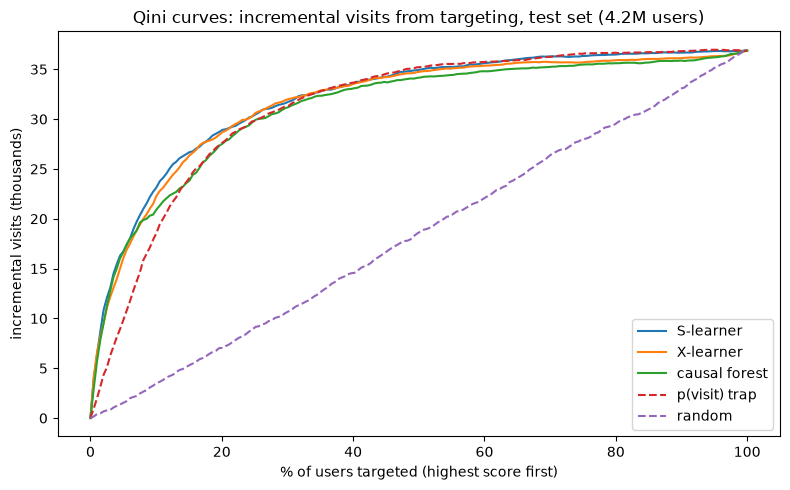

In [32]:
# 5C: Qini curve = extra visits caused by the ad vs share of users targeted
import matplotlib.pyplot as plt
def qini_curve(score, n_pts=200):
    o = np.argsort(-score); T, y = tte[o], yte[o]
    cyT, cnT = np.cumsum(y * T), np.cumsum(T)
    cyC, cnC = np.cumsum(y * (1 - T)), np.cumsum(1 - T)
    i = np.linspace(0, len(o) - 1, n_pts).astype(int)
    return (i + 1) / len(o), cyT[i] - cyC[i] * cnT[i] / np.maximum(cnC[i], 1)

fig, ax = plt.subplots(figsize=(8, 5))
for m in ["S-learner", "X-learner", "causal forest", "p(visit) trap", "random"]:
    f, q = qini_curve(res[m]); ax.plot(f * 100, q / 1000, label=m, ls="--" if m in ("random", "p(visit) trap") else "-")
ax.set(xlabel="% of users targeted (highest score first)", ylabel="incremental visits (thousands)",
       title="Qini curves: incremental visits from targeting, test set (4.2M users)")
ax.legend(); plt.tight_layout(); plt.show()

In [33]:
# Step 6A

# 6A: per-user AIPW score on TEST (outcome models t1/t0 were trained on train only, so no leakage)
p0 = p1 - up_t
psi_te = p1 - p0 + tte * (yte - p1) / e_te - (1 - tte) * (yte - p0) / (1 - e_te)
print(f"test AIPW lift: {psi_te.mean()*100:+.3f} pts ± {1.96 * psi_te.std() / np.sqrt(len(psi_te)) * 100:.3f}")

test AIPW lift: +0.762 pts ± 0.048


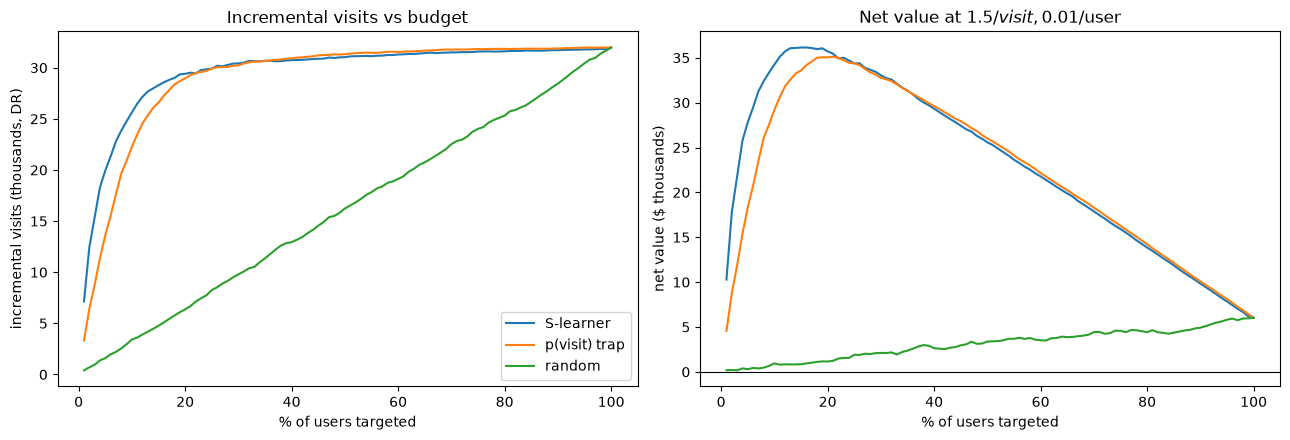

S-learner       best: target 16% | incremental visits 28,573 | net $36,149 | target everyone: $6,024
p(visit) trap   best: target 21% | incremental visits 29,278 | net $35,111 | target everyone: $6,024
random          best: target 100% | incremental visits 31,975 | net $6,024 | target everyone: $6,024


In [34]:
# 6B: value curves (ASSUMED economics: $ per incremental visit, $ per user targeted)
VALUE, COST = 1.50, 0.01
fracs = np.linspace(0.01, 1.0, 100)
def policy_curve(score, cost=COST):
    o = np.argsort(-score); cs = np.cumsum(psi_te[o])
    n = (fracs * len(o)).astype(int)
    inc = cs[n - 1]
    return inc, VALUE * inc - cost * n

curves = {m: policy_curve(res[m]) for m in ["S-learner", "p(visit) trap", "random"]}
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for m, (inc, net) in curves.items():
    ax[0].plot(fracs * 100, inc / 1000, label=m); ax[1].plot(fracs * 100, net / 1000, label=m)
ax[0].set(xlabel="% of users targeted", ylabel="incremental visits (thousands, DR)", title="Incremental visits vs budget")
ax[1].axhline(0, color="k", lw=0.8)
ax[1].set(xlabel="% of users targeted", ylabel="net value ($ thousands)", title=f"Net value at ${VALUE}/visit, ${COST}/user")
ax[0].legend(); plt.tight_layout(); plt.show()

for m, (inc, net) in curves.items():
    i = net.argmax()
    print(f"{m:15s} best: target {fracs[i]:.0%} | incremental visits {inc[i]:,.0f} | net ${net[i]:,.0f} "
          f"| target everyone: ${net[-1]:,.0f}")

In [35]:
# STEP 6C SENSITIVY OPTIMAL BUDGET AND VALUE WHEN THE COST PER USER CHANGES 
for c in [0.005, 0.01, 0.02]:
    out = []
    for m in ["S-learner", "p(visit) trap"]:
        inc, _ = curves[m]
        net = VALUE * inc - c * (fracs * len(yte)).astype(int); i = net.argmax()
        out.append(f"{m}: target {fracs[i]:.0%} -> ${net[i]:,.0f}")
    print(f"cost ${c}/user | " + " | ".join(out))

cost $0.005/user | S-learner: target 19% -> $40,038 | p(visit) trap: target 25% -> $39,630
cost $0.01/user | S-learner: target 16% -> $36,149 | p(visit) trap: target 21% -> $35,111
cost $0.02/user | S-learner: target 12% -> $30,680 | p(visit) trap: target 16% -> $27,470


In [36]:
#STEP 6D PAIRED BOOTDTRAP OF NET VALUE EACH POLICY AT ITS OWN BUDGET
iS, iT = curves["S-learner"][1].argmax(), curves["p(visit) trap"][1].argmax()
oS, oT = np.argsort(-res["S-learner"]), np.argsort(-res["p(visit) trap"])
nS, nT = int(fracs[iS] * len(yte)), int(fracs[iT] * len(yte))
diff = np.empty(200)
for b in range(200):
    w = np.random.default_rng(500 + b).poisson(1.0, len(yte))
    vS = VALUE * (w[oS[:nS]] * psi_te[oS[:nS]]).sum() - COST * w[oS[:nS]].sum()
    vT = VALUE * (w[oT[:nT]] * psi_te[oT[:nT]]).sum() - COST * w[oS[:nT]].sum()
    diff[b] = vS - vT
    
print(f"S-learner vs trap at their best budgets: +${diff.mean():,.0f} "
      f"[{np.percentile(diff, 2.5):,.0f}, {np.percentile(diff, 97.5):,.0f}] | S better in {(diff > 0).mean():.0%}")


S-learner vs trap at their best budgets: +$1,122 [-148, 2,321] | S better in 96%


In [37]:
# 7A: Hillstrom: load (tries the original site first, then the scikit-uplift mirror), audit, balance
import pandas as pd, numpy as np, lightgbm as lgb, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
URLS = ["http://www.minethatdata.com/Kevin_Hillstrom_MineThatData_E-MailAnalytics_DataMiningChallenge_2008.03.20.csv",
        "https://hillstorm1.s3.us-east-2.amazonaws.com/hillstorm_no_indices.csv.gz"]
for u in URLS:
    try:
        hs = pd.read_csv(u); print("loaded from", u); break
    except Exception as e:
        print("failed:", u, type(e).__name__)
hs.to_csv(Path.home() / "Documents/uplift/data/raw/hillstrom.csv", index=False)

print(hs.shape)
print(hs["segment"].value_counts())
print(hs.groupby("segment")[["visit", "conversion", "spend"]].mean().round(4))
print(f"buyers: {(hs['spend'] > 0).mean():.4f} | spend among buyers:",
      hs.loc[hs["spend"] > 0, "spend"].describe().round(1).to_dict())

X = pd.get_dummies(hs[["recency", "history", "mens", "womens", "newbie", "zip_code", "channel"]], dtype=float)
ctrl = (hs["segment"] == "No E-Mail").to_numpy()
for arm in ["Mens E-Mail", "Womens E-Mail"]:
    a = (hs["segment"] == arm).to_numpy()
    smd = (X[a].mean() - X[ctrl].mean()) / np.sqrt((X[a].var() + X[ctrl].var()) / 2)
    print(f"{arm}: max |SMD| {smd.abs().max():.3f} ({smd.abs().idxmax()})")

loaded from http://www.minethatdata.com/Kevin_Hillstrom_MineThatData_E-MailAnalytics_DataMiningChallenge_2008.03.20.csv
(64000, 12)
segment
Womens E-Mail    21387
Mens E-Mail      21307
No E-Mail        21306
Name: count, dtype: int64
                visit  conversion   spend
segment                                  
Mens E-Mail    0.1828      0.0125  1.4226
No E-Mail      0.1062      0.0057  0.6528
Womens E-Mail  0.1514      0.0088  1.0772
buyers: 0.0090 | spend among buyers: {'count': 578.0, 'mean': 116.4, 'std': 107.9, 'min': 30.0, '25%': 32.3, '50%': 80.8, '75%': 153.4, 'max': 499.0}
Mens E-Mail: max |SMD| 0.014 (zip_code_Rural)
Womens E-Mail: max |SMD| 0.009 (mens)


In [42]:
#7B 6 A/B TESTS WITH MULTIPLE-TESTING CORRECTION
from scipy import stats
from statsmodels.stats.multitest import multipletests

rows = []
for arm in ["Mens E-Mail", "Womens E-Mail"]:
    for out in ["visit", "conversion", "spend"]:
        a, c = hs.loc[hs["segment"] == arm, out], hs.loc[ctrl, out]
        d = a.mean() - c.mean(); se = np.sqrt(a.var() / len(a) + c.var() / len(c))
        rows.append((arm, out, c.mean(), a.mean(), d, d - 1.96 * se, d + 1.96 * se, 2 * stats.norm.sf(abs(d / se))))
        
ab = pd.DataFrame(rows, columns=["arm", "outcome", "control", "treated", "lift", "ci_lo", "ci_hi", "p"])
ab["p_holm"] = multipletests(ab["p"], method="holm")[1]
print(ab.round(4).to_string(index=False))
        

          arm    outcome  control  treated   lift  ci_lo  ci_hi      p  p_holm
  Mens E-Mail      visit   0.1062   0.1828 0.0766 0.0700 0.0832 0.0000  0.0000
  Mens E-Mail conversion   0.0057   0.0125 0.0068 0.0050 0.0086 0.0000  0.0000
  Mens E-Mail      spend   0.6528   1.4226 0.7698 0.4851 1.0545 0.0000  0.0000
Womens E-Mail      visit   0.1062   0.1514 0.0452 0.0389 0.0516 0.0000  0.0000
Womens E-Mail conversion   0.0057   0.0088 0.0031 0.0015 0.0047 0.0002  0.0003
Womens E-Mail      spend   0.6528   1.0772 0.4244 0.1690 0.6799 0.0011  0.0011


In [43]:
# 7C: S-learner, T-learner and the trap for each email, on visit and on spend
from sklearn.model_selection import StratifiedKFold
from sklift.metrics import qini_auc_score
P = dict(n_estimators=200, learning_rate=0.05, num_leaves=15, min_child_samples=100, verbose=-1)

def oof_uplift(arm, outcome):
    sub = hs["segment"].isin([arm, "No E-Mail"]).to_numpy()
    Xa = X[sub].reset_index(drop=True)
    Ta = (hs.loc[sub, "segment"] == arm).astype(int).to_numpy(); ya = hs.loc[sub, outcome].to_numpy()
    is_clf = outcome != "spend"
    M = lgb.LGBMClassifier if is_clf else lgb.LGBMRegressor
    pred = (lambda m, Z: m.predict_proba(Z)[:, 1]) if is_clf else (lambda m, Z: m.predict(Z))
    s_up, t_up, trap = np.zeros(len(ya)), np.zeros(len(ya)), np.zeros(len(ya))
    for tr, te in StratifiedKFold(5, shuffle=True, random_state=0).split(Xa, Ta * 2 + (ya > 0)):
        s = M(**P).fit(Xa.iloc[tr].assign(T=Ta[tr]), ya[tr])
        s_up[te] = pred(s, Xa.iloc[te].assign(T=1)) - pred(s, Xa.iloc[te].assign(T=0))
        m1 = M(**P).fit(Xa.iloc[tr][Ta[tr] == 1], ya[tr][Ta[tr] == 1])
        m0 = M(**P).fit(Xa.iloc[tr][Ta[tr] == 0], ya[tr][Ta[tr] == 0])
        trap[te] = pred(m1, Xa.iloc[te]); t_up[te] = trap[te] - pred(m0, Xa.iloc[te])
    return ya, Ta, {"S-learner": s_up, "T-learner": t_up, "trap": trap,
                    "random": np.random.default_rng(0).random(len(ya))}

def up_at(y, T, score, k, w=None):
    idx = np.argsort(-score)[:int(k * len(score))]
    ww = np.ones(len(idx)) if w is None else w[idx]
    Ti, yi = T[idx], y[idx]
    return (ww * Ti * yi).sum() / (ww * Ti).sum() - (ww * (1 - Ti) * yi).sum() / (ww * (1 - Ti)).sum()

for arm in ["Mens E-Mail", "Womens E-Mail"]:
    for out in ["visit", "spend"]:
        y_, T_, sc = oof_uplift(arm, out)
        for m, s in sc.items():
            q = qini_auc_score(y_, s, T_) if out == "visit" else np.nan
            print(f"{arm:14s} {out:6s} {m:10s} Qini {q:.4f} | top 10% {up_at(y_, T_, s, .1):+.4f} | top 30% {up_at(y_, T_, s, .3):+.4f}")
        d = np.array([up_at(y_, T_, sc["S-learner"], .3, w) - up_at(y_, T_, sc["trap"], .3, w)
                      for w in (np.random.default_rng(200 + b).poisson(1.0, len(y_)) for b in range(200))])
        print(f"   S minus trap, top 30%: {d.mean():+.4f} [{np.percentile(d, 2.5):+.4f}, {np.percentile(d, 97.5):+.4f}] "
              f"| S better in {(d > 0).mean():.0%}\n")

Mens E-Mail    visit  S-learner  Qini 0.0128 | top 10% +0.1199 | top 30% +0.0862
Mens E-Mail    visit  T-learner  Qini 0.0013 | top 10% +0.0967 | top 30% +0.0807
Mens E-Mail    visit  trap       Qini 0.0243 | top 10% +0.1115 | top 30% +0.0896
Mens E-Mail    visit  random     Qini 0.0069 | top 10% +0.0689 | top 30% +0.0842
   S minus trap, top 30%: -0.0033 [-0.0152, +0.0086] | S better in 28%

Mens E-Mail    spend  S-learner  Qini nan | top 10% +0.9608 | top 30% +0.7080
Mens E-Mail    spend  T-learner  Qini nan | top 10% +1.2453 | top 30% +0.9296
Mens E-Mail    spend  trap       Qini nan | top 10% +1.2091 | top 30% +0.8141
Mens E-Mail    spend  random     Qini nan | top 10% +0.6923 | top 30% +0.8194
   S minus trap, top 30%: -0.1521 [-0.6907, +0.3008] | S better in 28%

Womens E-Mail  visit  S-learner  Qini 0.0645 | top 10% +0.0757 | top 30% +0.0767
Womens E-Mail  visit  T-learner  Qini 0.0461 | top 10% +0.0727 | top 30% +0.0677
Womens E-Mail  visit  trap       Qini 0.0319 | top 10% +0.

In [46]:
#STEP 7D CHOOSE NO EMAIL, MENS OR WOMENS FOR EACH CUSTOMER; VALUE THE POLICY WITH EXACT (PROPENSITY 1/3)

arms = ["No E-Mail" , "Mens E-Mail", "Womens E-Mail"]
A = hs["segment"].map({a:i for i, a in enumerate(arms)}).to_numpy()
spend = hs["spend"].to_numpy(); Xall = X.reset_index(drop = True)
pred_sp = np.zeros((len(hs), 3))
for tr, te in StratifiedKFold(5, shuffle = True, random_state = 1).split(Xall, A):
    m = lgb.LGBMRegressor(**P).fit(Xall.iloc[tr].assign(A=A[tr]), spend[tr])
    for k in range(3):
        pred_sp[te, k] = m.predict(Xall.iloc[te].assign(A=k))
        
MARGIN, EMAIL_COST = .30, .10
cost = np.array([0.0, EMAIL_COST, EMAIL_COST])
profit = MARGIN * spend - cost[A]
targeted = (MARGIN + pred_sp - cost).argmax(axis=1)

def value(policy, w = None):
    w = np.ones(len(A)) if w is None else w
    match = (A == policy)
    return ( w * match * profit).sum() / (w *match).sum()
pols = {"email no one": np.zeros(len(A),int),  "everyone: mens": np.ones(len(A), int),
        "everyone womens": np.full(len(A),2), "targerted": targeted}

print("targeted mix:", pd.Series(targeted).map(dict(enumerate(arms))).value_counts().to_dict())

best_fixed = max([k for k in pols if k != "targeted"], key=lambda k: value(pols[k]))
d = np.array([value(targeted, w) - value(pols[best_fixed], w)
              for w in (np.random.default_rng(900 + b).poisson(1.0, len(A)) for b in range(200))])
print(f"targeted minus best single policy ({best_fixed}): ${d.mean() * 64000:+,.0f} per 64k "
      f"[{np.percentile(d, 2.5) * 64000:+,.0f}, {np.percentile(d, 97.5) * 64000:+,.0f}] | better in {(d > 0).mean():.0%}")

targeted mix: {'Mens E-Mail': 46246, 'Womens E-Mail': 13145, 'No E-Mail': 4609}
targeted minus best single policy (everyone: mens): $-2,799 per 64k [-5,790, +388] | better in 4%
